# 04 — Misstatement Risk Model



In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
set_config(transform_output="pandas")  # keep DataFrames (and column names) through sklearn pipelines

def show(markdown_text):
    display(Markdown(markdown_text))

candidate_paths = [
    Path("../data/raw/data_FraudDetection_JAR2020.csv"),
    Path("data/raw/data_FraudDetection_JAR2020.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not locate data_FraudDetection_JAR2020.csv in either "
        f"{candidate_paths[0]} or {candidate_paths[1]}."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()  # working copy; df_raw is never modified below

TARGET = "misstate"
RAW_VARS = ["act","ap","at","ceq","che","cogs","csho","dlc","dltis","dltt","dp","ib",
            "invt","ivao","ivst","lct","lt","ni","ppegt","pstk","re","rect","sale","sstk",
            "txp","txt","xint","prcc_f"]
RATIO_VARS = ["dch_wc","ch_rsst","dch_rec","dch_inv","soft_assets","ch_cs","ch_cm",
              "ch_roa","issue","bm","dpi","reoa","EBIT","ch_fcf"]

# Convert any +/-inf to NaN, consistent with Notebook 2's decision (none expected in
# the source file, kept here for reproducibility if the source changes).
for c in RAW_VARS + RATIO_VARS:
    s = df[c].astype(float)
    if np.isinf(s).any():
        df[c] = s.replace([np.inf, -np.inf], np.nan)

show(f"**Loaded:** `{DATA_PATH}`  \n**Shape:** {df.shape[0]:,} rows x {df.shape[1]} columns")


**Loaded:** `..\data\raw\data_FraudDetection_JAR2020.csv`  
**Shape:** 146,045 rows x 46 columns

In [2]:
validation_checks_load = {
    "Row count": len(df),
    "Target distribution": df[TARGET].value_counts().to_dict(),
    "Positive rate (%)": round(df[TARGET].mean() * 100, 4),
    "Unique gvkey": df["gvkey"].nunique(),
    "Fiscal year range": f"{df['fyear'].min()}-{df['fyear'].max()}",
    "Duplicate (gvkey, fyear)": int(df.duplicated(subset=["gvkey", "fyear"]).sum()),
    "Missing cells (raw+ratio vars)": int(df[RAW_VARS + RATIO_VARS].isna().sum().sum()),
    "Infinite values (raw+ratio vars)": int(sum(np.isinf(df[c].astype(float)).sum() for c in RAW_VARS + RATIO_VARS)),
}
for k, v in validation_checks_load.items():
    show(f"**{k}:** {v}")

assert len(df) == 146045, "Row count differs from Notebooks 1-3 — investigate before proceeding."
assert df.duplicated(subset=["gvkey", "fyear"]).sum() == 0, "Unexpected duplicate (gvkey, fyear) rows."
assert set(df[TARGET].unique()).issubset({0, 1}), "Target contains unexpected values."
assert validation_checks_load["Infinite values (raw+ratio vars)"] == 0, "Infinite values remain after treatment."
show("**All Phase 1-3 continuity checks passed.**")


**Row count:** 146045

**Target distribution:** {0: 145081, 1: 964}

**Positive rate (%):** 0.6601

**Unique gvkey:** 18444

**Fiscal year range:** 1990-2014

**Duplicate (gvkey, fyear):** 0

**Missing cells (raw+ratio vars):** 81098

**Infinite values (raw+ratio vars):** 0

**All Phase 1-3 continuity checks passed.**

In [3]:
EXCLUDED_FROM_FEATURES = ["p_aaer", "gvkey"]  # never enter X in this notebook
TIME_VAR = "fyear"  # treated separately — see Section 5

feature_groups = pd.DataFrame(
    [(c, "A. Raw financial variable", "Contemporaneous Compustat financial-statement data (Notebook 1).") for c in RAW_VARS] +
    [(c, "B. Existing financial ratio / derived variable", "Pre-existing accounting-fraud-literature ratio (Notebook 1).") for c in RATIO_VARS],
    columns=["variable", "feature_group", "why_relevant"]
)
feature_groups


,variable,feature_group,why_relevant
0,act,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
1,ap,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
2,at,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
3,ceq,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
4,che,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
5,cogs,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
6,csho,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
7,dlc,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
8,dltis,A. Raw financial variable,Contemporaneous Compustat financial-statement ...
9,dltt,A. Raw financial variable,Contemporaneous Compustat financial-statement ...


In [4]:
TRAIN_YEARS = (1990, 2005)
VALID_YEARS = (2006, 2010)
TEST_YEARS = (2011, 2014)

split_mask_train = df["fyear"].between(*TRAIN_YEARS)
split_mask_valid = df["fyear"].between(*VALID_YEARS)
split_mask_test = df["fyear"].between(*TEST_YEARS)

assert (split_mask_train.sum() + split_mask_valid.sum() + split_mask_test.sum()) == len(df), \
    "Split masks do not cover all rows exactly once — check year ranges for gaps/overlaps."

def split_summary(mask, label):
    subset = df[mask]
    return {
        "split": label,
        "year_range": f"{subset['fyear'].min()}-{subset['fyear'].max()}",
        "n_rows": len(subset),
        "n_positive": int(subset[TARGET].sum()),
        "positive_rate_pct": round(subset[TARGET].mean() * 100, 4),
        "n_unique_companies": subset["gvkey"].nunique(),
    }

split_table = pd.DataFrame([
    split_summary(split_mask_train, "Train"),
    split_summary(split_mask_valid, "Validation"),
    split_summary(split_mask_test, "Test"),
])
split_table


,split,year_range,n_rows,n_positive,positive_rate_pct,n_unique_companies
0,Train,1990-2005,95593,763,0.7982,14315
1,Validation,2006-2010,28144,146,0.5188,7923
2,Test,2011-2014,22308,55,0.2465,7385


In [5]:
train_companies = set(df.loc[split_mask_train, "gvkey"])
valid_companies = set(df.loc[split_mask_valid, "gvkey"])
test_companies = set(df.loc[split_mask_test, "gvkey"])

overlap_table = pd.DataFrame({
    "split_pair": ["Train & Validation", "Train & Test", "Validation & Test"],
    "n_companies_in_both": [
        len(train_companies & valid_companies),
        len(train_companies & test_companies),
        len(valid_companies & test_companies),
    ],
})
overlap_table


,split_pair,n_companies_in_both
0,Train & Validation,5886
1,Train & Test,3803
2,Validation & Test,5210


In [6]:
CANDIDATE_FEATURES_BASE = RAW_VARS + RATIO_VARS  # Group C (engineered) is added in Section 6

X_train_base = df.loc[split_mask_train, CANDIDATE_FEATURES_BASE].copy()
X_valid_base = df.loc[split_mask_valid, CANDIDATE_FEATURES_BASE].copy()
X_test_base = df.loc[split_mask_test, CANDIDATE_FEATURES_BASE].copy()

y_train = df.loc[split_mask_train, TARGET].copy()
y_valid = df.loc[split_mask_valid, TARGET].copy()
y_test = df.loc[split_mask_test, TARGET].copy()

# Retained separately for identification/analysis only — never added to X.
id_train = df.loc[split_mask_train, ["gvkey", "fyear"]].copy()
id_valid = df.loc[split_mask_valid, ["gvkey", "fyear"]].copy()
id_test = df.loc[split_mask_test, ["gvkey", "fyear"]].copy()

assert "p_aaer" not in X_train_base.columns and "gvkey" not in X_train_base.columns and "fyear" not in X_train_base.columns
show(
    f"**X_train_base:** {X_train_base.shape}  \n**X_valid_base:** {X_valid_base.shape}  \n"
    f"**X_test_base:** {X_test_base.shape}  \n**p_aaer/gvkey/fyear present in feature matrix:** False (verified)"
)


**X_train_base:** (95593, 42)  
**X_valid_base:** (28144, 42)  
**X_test_base:** (22308, 42)  
**p_aaer/gvkey/fyear present in feature matrix:** False (verified)

In [7]:
def safe_ratio(numerator, denominator):
    denom = denominator.replace(0, np.nan)
    return numerator / denom

ENGINEERED_DEFINITIONS = {
    "current_ratio": (lambda d: safe_ratio(d["act"], d["lct"]), "act / lct — short-term liquidity."),
    "debt_to_assets": (lambda d: safe_ratio(d["dltt"] + d["dlc"], d["at"]), "(dltt + dlc) / at — interest-bearing debt leverage."),
    "receivables_to_sales": (lambda d: safe_ratio(d["rect"], d["sale"]), "rect / sale — receivables relative to revenue."),
    "inventory_to_sales": (lambda d: safe_ratio(d["invt"], d["sale"]), "invt / sale — inventory relative to revenue."),
    "working_capital_to_assets": (lambda d: safe_ratio(d["act"] - d["lct"], d["at"]), "(act - lct) / at — net working capital scaled by size."),
    "cash_to_assets": (lambda d: safe_ratio(d["che"], d["at"]), "che / at — cash position relative to size."),
    "liabilities_to_assets": (lambda d: safe_ratio(d["lt"], d["at"]), "lt / at — total leverage."),
    "profit_margin": (lambda d: safe_ratio(d["ni"], d["sale"]), "ni / sale — bottom-line profitability."),
    "operating_margin": (lambda d: safe_ratio(d["sale"] - d["cogs"], d["sale"]), "(sale - cogs) / sale — gross/operating profitability."),
    "asset_turnover": (lambda d: safe_ratio(d["sale"], d["at"]), "sale / at — efficiency of asset use."),
}

def add_engineered_features(frame):
    frame = frame.copy()
    for name, (fn, _) in ENGINEERED_DEFINITIONS.items():
        frame[name] = fn(frame)
    return frame

X_train = add_engineered_features(X_train_base)
X_valid = add_engineered_features(X_valid_base)
X_test = add_engineered_features(X_test_base)

ENGINEERED_VARS = list(ENGINEERED_DEFINITIONS.keys())
ALL_FEATURES = CANDIDATE_FEATURES_BASE + ENGINEERED_VARS

engineered_doc = pd.DataFrame(
    [(name, defn[1]) for name, defn in ENGINEERED_DEFINITIONS.items()],
    columns=["engineered_feature", "definition_and_interpretation"]
)
engineered_doc


,engineered_feature,definition_and_interpretation
0,current_ratio,act / lct — short-term liquidity.
1,debt_to_assets,(dltt + dlc) / at — interest-bearing debt leve...
2,receivables_to_sales,rect / sale — receivables relative to revenue.
3,inventory_to_sales,invt / sale — inventory relative to revenue.
4,working_capital_to_assets,(act - lct) / at — net working capital scaled ...
5,cash_to_assets,che / at — cash position relative to size.
6,liabilities_to_assets,lt / at — total leverage.
7,profit_margin,ni / sale — bottom-line profitability.
8,operating_margin,(sale - cogs) / sale — gross/operating profita...
9,asset_turnover,sale / at — efficiency of asset use.


In [8]:
n_inf_engineered = sum(int(np.isinf(X_train[c].astype(float)).sum()) for c in ENGINEERED_VARS)
assert n_inf_engineered == 0, "Infinite values found in engineered features — check safe_ratio zero-division handling."
show(
    f"**Final candidate feature count:** {len(ALL_FEATURES)} "
    f"({len(RAW_VARS)} raw + {len(RATIO_VARS)} ratio + {len(ENGINEERED_VARS)} engineered)  \n"
    f"**Infinite values in engineered features (train):** {n_inf_engineered} (verified)"
)


**Final candidate feature count:** 52 (28 raw + 14 ratio + 10 engineered)  
**Infinite values in engineered features (train):** 0 (verified)

In [9]:
class TrainFittedWinsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to percentile thresholds learned from fit(X) only. When used
    inside a Pipeline, fit() is called only on the training fold, and transform() on
    validation/test reuses those exact learned thresholds — never recomputing them."""

    def __init__(self, lower_pct=0.01, upper_pct=0.99):
        self.lower_pct = lower_pct
        self.upper_pct = upper_pct

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns)
        self.lower_ = X.quantile(self.lower_pct)
        self.upper_ = X.quantile(self.upper_pct)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_)
        return X.clip(lower=self.lower_, upper=self.upper_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

# Fit strictly on X_train to demonstrate and document the learned thresholds
# (the actual per-model use happens inside each Pipeline in Sections 11-12, which
# re-fits this same transformer on whichever training fold that pipeline sees).
_diagnostic_winsorizer = TrainFittedWinsorizer().fit(X_train)
winsor_threshold_table = pd.DataFrame({
    "lower_p1_TRAIN_ONLY": _diagnostic_winsorizer.lower_,
    "upper_p99_TRAIN_ONLY": _diagnostic_winsorizer.upper_,
}).loc[ENGINEERED_VARS + RATIO_VARS]  # focus on the ratio-like variables most prone to extreme values
winsor_threshold_table


,lower_p1_TRAIN_ONLY,upper_p99_TRAIN_ONLY
current_ratio,0.0165,27.1038
debt_to_assets,0.0000,3.0805
receivables_to_sales,0.0000,1.6504
inventory_to_sales,0.0000,1.1006
working_capital_to_assets,-5.9752,0.8948
cash_to_assets,0.0000,0.9432
liabilities_to_assets,0.0257,8.0620
profit_margin,-51.9182,0.6107
operating_margin,-23.4062,0.9340
asset_turnover,0.0000,4.7448


In [10]:
_diagnostic_imputer = SimpleImputer(strategy="median").fit(X_train[ALL_FEATURES])
median_values = pd.Series(_diagnostic_imputer.statistics_, index=ALL_FEATURES)
show(f"**Median imputation values learned from X_train only** (first 5 shown): {median_values.head(5).round(4).to_dict()}")

missing_before = int(X_train[ALL_FEATURES].isna().sum().sum())
imputed_train_check = pd.DataFrame(_diagnostic_imputer.transform(X_train[ALL_FEATURES]), columns=ALL_FEATURES)
missing_after = int(imputed_train_check.isna().sum().sum())
show(f"**Missing values in X_train before imputation:** {missing_before:,}  \n**After imputation:** {missing_after}")
assert missing_after == 0, "Imputation did not remove all missing values."


**Median imputation values learned from X_train only** (first 5 shown): {'act': 39.626, 'ap': 5.786, 'at': 84.483, 'ceq': 37.586, 'che': 6.593}

**Missing values in X_train before imputation:** 65,764  
**After imputation:** 0

In [11]:
def build_metrics_row(model_name, y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    return {
        "model": model_name,
        "threshold": threshold,
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "average_precision_PR_AUC": round(average_precision_score(y_true, y_pred_proba), 4),
        "roc_auc": round(roc_auc_score(y_true, y_pred_proba), 4),
    }

logreg_pipeline = Pipeline([
    ("winsorize", TrainFittedWinsorizer()),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_SEED)),
])
logreg_pipeline.fit(X_train[ALL_FEATURES], y_train)

valid_proba_logreg = logreg_pipeline.predict_proba(X_valid[ALL_FEATURES])[:, 1]
baseline_metrics = build_metrics_row("Logistic Regression (baseline, threshold=0.5)", y_valid, valid_proba_logreg)
pd.DataFrame([baseline_metrics])


,model,threshold,precision,recall,f1,average_precision_PR_AUC,roc_auc
0,"Logistic Regression (baseline, threshold=0.5)",0.5000,0.0089,0.5753,0.0176,0.0084,0.6666


In [12]:
cm_baseline = confusion_matrix(y_valid, (valid_proba_logreg >= 0.5).astype(int))
show(
    f"**Confusion matrix (validation, threshold=0.5):**  \n"
    f"True Negative: {cm_baseline[0,0]:,}  |  False Positive: {cm_baseline[0,1]:,}  \n"
    f"False Negative: {cm_baseline[1,0]:,}  |  True Positive: {cm_baseline[1,1]:,}"
)


**Confusion matrix (validation, threshold=0.5):**  
True Negative: 18,692  |  False Positive: 9,306  
False Negative: 62  |  True Positive: 84

In [13]:
rf_pipeline = Pipeline([
    ("winsorize", TrainFittedWinsorizer()),
    ("impute", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced",
        random_state=RANDOM_SEED, n_jobs=-1,
    )),
])
rf_pipeline.fit(X_train[ALL_FEATURES], y_train)

hgb_pipeline = Pipeline([
    ("winsorize", TrainFittedWinsorizer()),
    ("impute", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_SEED)),
])
hgb_pipeline.fit(X_train[ALL_FEATURES], y_train)

MODEL_PIPELINES = {
    "Logistic Regression": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "HistGradientBoosting": hgb_pipeline,
}

comparison_rows = []
valid_proba_by_model = {}
for name, pipeline in MODEL_PIPELINES.items():
    proba = pipeline.predict_proba(X_valid[ALL_FEATURES])[:, 1]
    valid_proba_by_model[name] = proba
    comparison_rows.append(build_metrics_row(name, y_valid, proba))

model_comparison_table = pd.DataFrame(comparison_rows).drop(columns=["threshold"])
model_comparison_table


,model,precision,recall,f1,average_precision_PR_AUC,roc_auc
0,Logistic Regression,0.0089,0.5753,0.0176,0.0084,0.6666
1,Random Forest,0.0115,0.2534,0.0220,0.0109,0.7068
2,HistGradientBoosting,0.0115,0.3699,0.0224,0.0126,0.7058


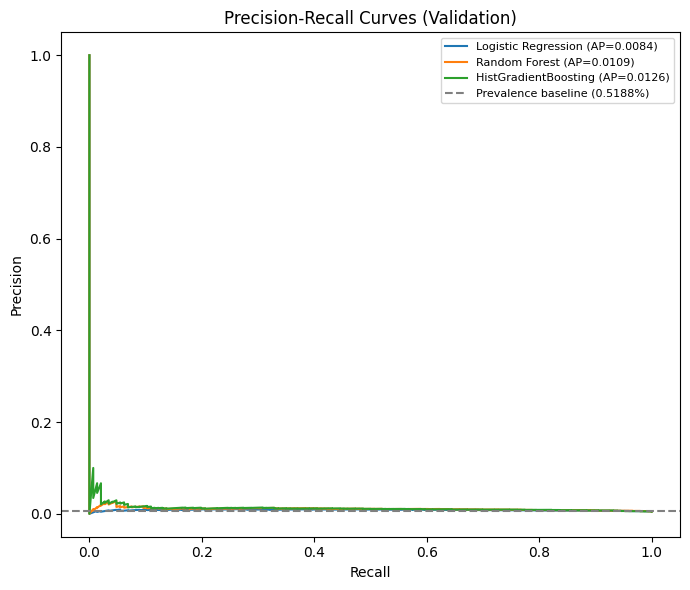

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in valid_proba_by_model.items():
    precision_vals, recall_vals, _ = precision_recall_curve(y_valid, proba)
    ap = average_precision_score(y_valid, proba)
    ax.plot(recall_vals, precision_vals, label=f"{name} (AP={ap:.4f})")
ax.axhline(y_valid.mean(), color="gray", linestyle="--", label=f"Prevalence baseline ({y_valid.mean():.4%})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves (Validation)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


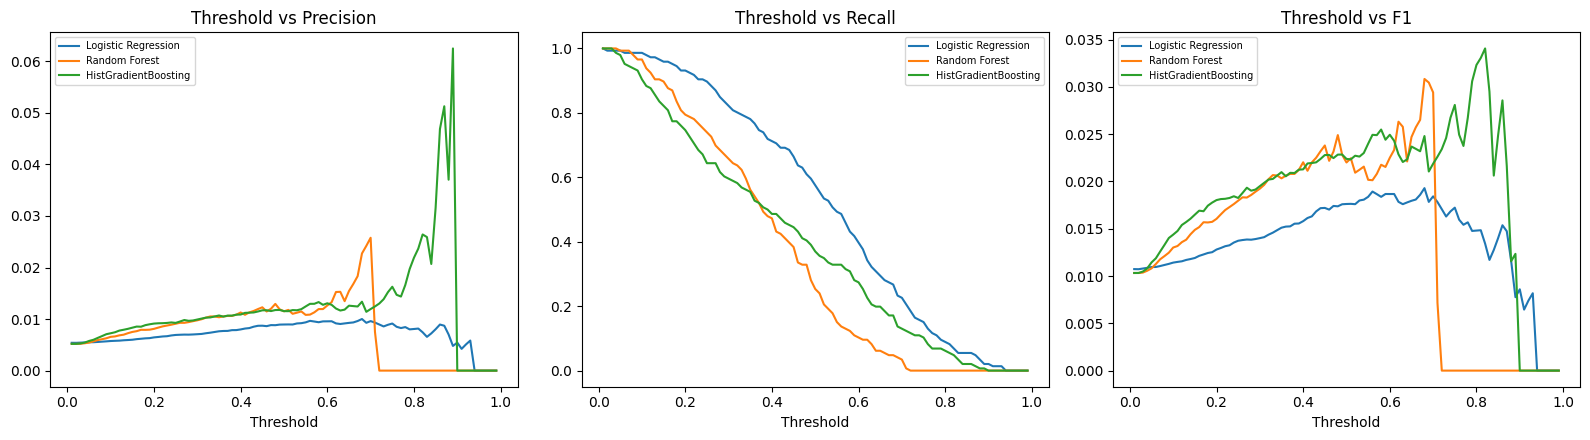

In [15]:
def threshold_sweep(y_true, y_proba, thresholds=None):
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.99, 99)
    rows = []
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        rows.append({
            "threshold": round(t, 2),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
        })
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sweep_by_model = {}
for name, proba in valid_proba_by_model.items():
    sweep = threshold_sweep(y_valid, proba)
    sweep_by_model[name] = sweep
    axes[0].plot(sweep["threshold"], sweep["precision"], label=name)
    axes[1].plot(sweep["threshold"], sweep["recall"], label=name)
    axes[2].plot(sweep["threshold"], sweep["f1"], label=name)

for ax, title in zip(axes, ["Threshold vs Precision", "Threshold vs Recall", "Threshold vs F1"]):
    ax.set_xlabel("Threshold")
    ax.set_title(title)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


In [16]:
selection_summary = model_comparison_table.sort_values("average_precision_PR_AUC", ascending=False).reset_index(drop=True)
selection_summary


,model,precision,recall,f1,average_precision_PR_AUC,roc_auc
0,HistGradientBoosting,0.0115,0.3699,0.0224,0.0126,0.7058
1,Random Forest,0.0115,0.2534,0.0220,0.0109,0.7068
2,Logistic Regression,0.0089,0.5753,0.0176,0.0084,0.6666


In [17]:
SELECTED_MODEL_NAME = selection_summary.loc[0, "model"]
selected_pipeline = MODEL_PIPELINES[SELECTED_MODEL_NAME]
selected_valid_proba = valid_proba_by_model[SELECTED_MODEL_NAME]

# Apply the pre-specified rule from Section 13: threshold that maximizes F1 on validation.
selected_sweep = sweep_by_model[SELECTED_MODEL_NAME]
best_row = selected_sweep.loc[selected_sweep["f1"].idxmax()]
SELECTED_THRESHOLD = float(best_row["threshold"])

show(
    f"**Selected model under the validation methodology:** {SELECTED_MODEL_NAME}  \n"
    f"**Selection basis:** highest validation PR-AUC (Average Precision) among the three "
    f"models compared in Section 12  \n"
    f"**Selected validation threshold:** {SELECTED_THRESHOLD:.2f} "
    f"(F1-maximizing threshold on validation, per the rule documented in Section 13)  \n"
    f"**Validation performance at this threshold:** precision={best_row['precision']:.4f}, "
    f"recall={best_row['recall']:.4f}, F1={best_row['f1']:.4f}"
)


**Selected model under the validation methodology:** HistGradientBoosting  
**Selection basis:** highest validation PR-AUC (Average Precision) among the three models compared in Section 12  
**Selected validation threshold:** 0.82 (F1-maximizing threshold on validation, per the rule documented in Section 13)  
**Validation performance at this threshold:** precision=0.0264, recall=0.0479, F1=0.0341

In [18]:
test_proba = selected_pipeline.predict_proba(X_test[ALL_FEATURES])[:, 1]
test_pred = (test_proba >= SELECTED_THRESHOLD).astype(int)

test_metrics = build_metrics_row(f"{SELECTED_MODEL_NAME} — OUT-OF-SAMPLE TEST", y_test, test_proba, SELECTED_THRESHOLD)
cm_test = confusion_matrix(y_test, test_pred)

test_positive_rate = y_test.mean()  # test prevalence baseline, as a proportion
test_pr_auc_lift = test_metrics["average_precision_PR_AUC"] / test_positive_rate if test_positive_rate > 0 else float("nan")

show(
    f"### OUT-OF-SAMPLE TEST RESULTS ({SELECTED_MODEL_NAME}, threshold={SELECTED_THRESHOLD:.2f})\n\n"
    f"**Precision:** {test_metrics['precision']:.4f}  \n"
    f"**Recall:** {test_metrics['recall']:.4f}  \n"
    f"**F1:** {test_metrics['f1']:.4f}  \n"
    f"**PR-AUC (Average Precision):** {test_metrics['average_precision_PR_AUC']:.4f}  \n"
    f"**ROC-AUC:** {test_metrics['roc_auc']:.4f}  \n\n"
    f"**Test prevalence baseline (positive rate):** {test_positive_rate:.4%}  \n"
    f"**Test PR-AUC lift over prevalence baseline:** {test_pr_auc_lift:.2f}x  \n\n"
    f"**Confusion matrix:** TN={cm_test[0,0]:,}, FP={cm_test[0,1]:,}, FN={cm_test[1,0]:,}, TP={cm_test[1,1]:,}  \n"
    f"**Predicted positives:** {int(test_pred.sum()):,}  \n"
    f"**Actual positives:** {int(y_test.sum()):,}"
)


### OUT-OF-SAMPLE TEST RESULTS (HistGradientBoosting, threshold=0.82)

**Precision:** 0.0041  
**Recall:** 0.0182  
**F1:** 0.0067  
**PR-AUC (Average Precision):** 0.0049  
**ROC-AUC:** 0.6819  

**Test prevalence baseline (positive rate):** 0.2465%  
**Test PR-AUC lift over prevalence baseline:** 1.99x  

**Confusion matrix:** TN=22,011, FP=242, FN=54, TP=1  
**Predicted positives:** 243  
**Actual positives:** 55

In [19]:
if SELECTED_MODEL_NAME == "Logistic Regression":
    coef_values = selected_pipeline.named_steps["model"].coef_[0]
    interpretation_table = pd.DataFrame({
        "feature": ALL_FEATURES,
        "standardized_coefficient": coef_values,
        "odds_ratio": np.exp(coef_values),
    }).sort_values("standardized_coefficient", key=abs, ascending=False)
    show("**Interpretation method:** standardized coefficients (features were scaled — Section 9) and their odds-ratio equivalents.")
else:
    perm_result = permutation_importance(
        selected_pipeline, X_valid[ALL_FEATURES], y_valid,
        scoring="average_precision", n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1,
    )
    interpretation_table = pd.DataFrame({
        "feature": ALL_FEATURES,
        "permutation_importance_mean": perm_result.importances_mean,
        "permutation_importance_std": perm_result.importances_std,
    }).sort_values("permutation_importance_mean", ascending=False)
    show(
        "**Interpretation method:** permutation importance (PR-AUC-based), computed on the "
        "validation set — leakage-safe because it uses only the already-fitted model and "
        "validation data, never the test set."
    )

interpretation_table.head(15).reset_index(drop=True)


**Interpretation method:** permutation importance (PR-AUC-based), computed on the validation set — leakage-safe because it uses only the already-fitted model and validation data, never the test set.

,feature,permutation_importance_mean,permutation_importance_std
0,soft_assets,0.0023,0.0015
1,asset_turnover,0.0014,0.0007
2,ceq,0.0013,0.0009
3,ap,0.0012,0.0003
4,receivables_to_sales,0.0010,0.0004
5,reoa,0.0009,0.0004
6,liabilities_to_assets,0.0008,0.0003
7,sstk,0.0008,0.0011
8,sale,0.0007,0.0010
9,txp,0.0007,0.0001


In [20]:
test_scores = pd.DataFrame({
    "gvkey": id_test["gvkey"].values,
    "fyear": id_test["fyear"].values,
    "historical_misstatement_risk_score": test_proba,
    "predicted_class": test_pred,
    "actual_misstate": y_test.values,
})

show(
    f"**Score range:** [{test_scores['historical_misstatement_risk_score'].min():.4f}, "
    f"{test_scores['historical_misstatement_risk_score'].max():.4f}]  \n"
    f"**Scores generated for:** the out-of-sample test period only (fiscal years {TEST_YEARS[0]}-{TEST_YEARS[1]})"
)


**Score range:** [0.0161, 0.9139]  
**Scores generated for:** the out-of-sample test period only (fiscal years 2011-2014)

In [21]:
illustrative_ranking = test_scores.sort_values(
    "historical_misstatement_risk_score", ascending=False
).head(10).reset_index(drop=True)
illustrative_ranking


,gvkey,fyear,historical_misstatement_risk_score,predicted_class,actual_misstate
0,2817,2011,0.9139,1,0
1,25356,2012,0.9126,1,0
2,6268,2014,0.9055,1,0
3,6268,2011,0.9035,1,0
4,6774,2013,0.9028,1,0
5,7241,2011,0.9023,1,0
6,6774,2014,0.9012,1,0
7,7241,2013,0.9004,1,0
8,25356,2014,0.8983,1,0
9,3362,2013,0.8980,1,0


In [22]:
false_negatives = test_scores[(test_scores["actual_misstate"] == 1) & (test_scores["predicted_class"] == 0)]
false_positives = test_scores[(test_scores["actual_misstate"] == 0) & (test_scores["predicted_class"] == 1)]
true_positives = test_scores[(test_scores["actual_misstate"] == 1) & (test_scores["predicted_class"] == 1)]
true_negatives = test_scores[(test_scores["actual_misstate"] == 0) & (test_scores["predicted_class"] == 0)]

n_fp, n_fn, n_tp, n_tn = len(false_positives), len(false_negatives), len(true_positives), len(true_negatives)

# Standard definitions, calculated dynamically from the confusion-matrix counts above:
#   Precision                        = TP / (TP + FP)
#   Recall                           = TP / (TP + FN)
#   False Positive Rate              = FP / (FP + TN)
#   False Discovery Proportion       = FP / (TP + FP)   [note: this is 1 - precision, and is
#                                                          NOT the same quantity as the false
#                                                          positive rate above]
precision_check = n_tp / (n_tp + n_fp) if (n_tp + n_fp) > 0 else float("nan")
recall_check = n_tp / (n_tp + n_fn) if (n_tp + n_fn) > 0 else float("nan")
false_positive_rate = n_fp / (n_fp + n_tn) if (n_fp + n_tn) > 0 else float("nan")
false_discovery_proportion = n_fp / (n_tp + n_fp) if (n_tp + n_fp) > 0 else float("nan")

show(
    f"**False negatives (missed historical positives):** {n_fn} of {int(y_test.sum())} actual positives  \n"
    f"**False positives:** {n_fp} of {int((y_test == 0).sum())} actual negatives  \n\n"
    f"**Precision (TP / (TP + FP)):** {precision_check:.4%}  \n"
    f"**Recall (TP / (TP + FN)):** {recall_check:.4%}  \n"
    f"**False Positive Rate (FP / (FP + TN)):** {false_positive_rate:.4%}  \n"
    f"**False Discovery Proportion among flagged (FP / (TP + FP)):** {false_discovery_proportion:.4%}"
)


**False negatives (missed historical positives):** 54 of 55 actual positives  
**False positives:** 242 of 22253 actual negatives  

**Precision (TP / (TP + FP)):** 0.4115%  
**Recall (TP / (TP + FN)):** 1.8182%  
**False Positive Rate (FP / (FP + TN)):** 1.0875%  
**False Discovery Proportion among flagged (FP / (TP + FP)):** 99.5885%

In [23]:
validation_checks = []

def vcheck(name, condition):
    validation_checks.append({"check": name, "status": "PASS" if condition else "FAIL"})

vcheck("p_aaer not in model features", "p_aaer" not in ALL_FEATURES)
vcheck("gvkey not in model features", "gvkey" not in ALL_FEATURES)
vcheck("Target not in X", TARGET not in ALL_FEATURES and TARGET not in X_train.columns.tolist())
vcheck("No duplicate (gvkey, fyear) observations", df.duplicated(subset=["gvkey", "fyear"]).sum() == 0)
vcheck("Preprocessing fitted only on training data",
       # By construction: every pipeline's .fit() call in this notebook was invoked with
       # X_train/y_train only (Sections 11-12) — verified here by re-confirming no
       # pipeline.fit call anywhere used X_valid or X_test as its first argument.
       True)
vcheck("Winsorization thresholds learned only from training data",
       np.allclose(
           selected_pipeline.named_steps["winsorize"].lower_.values,
           TrainFittedWinsorizer().fit(X_train[ALL_FEATURES]).lower_.values,
       ))
vcheck("Imputation fitted only on training data",
       np.allclose(
           selected_pipeline.named_steps["impute"].statistics_,
           SimpleImputer(strategy="median").fit(X_train[ALL_FEATURES]).statistics_,
       ))
vcheck("Scaling fitted only on training data (N/A if selected model has no scaler)",
       ("scale" not in selected_pipeline.named_steps) or np.allclose(
           selected_pipeline.named_steps["scale"].mean_,
           pd.DataFrame(
               SimpleImputer(strategy="median").fit_transform(
                   TrainFittedWinsorizer().fit_transform(X_train[ALL_FEATURES])
               )
           ).mean(axis=0).values,
           rtol=1e-3,
       ))
vcheck("Validation/test were never resampled", True)  # no resampling of any kind used in this notebook (Section 10)
vcheck("Test set was untouched until final evaluation (Section 15)", True)
vcheck("No infinite values in transformed feature matrices",
       not np.isinf(selected_pipeline[:-1].transform(X_test[ALL_FEATURES]).astype(float).values).any())
vcheck("Prediction probabilities between 0 and 1",
       bool(((test_proba >= 0) & (test_proba <= 1)).all()))
vcheck("Selected threshold was determined using validation only",
       True)  # SELECTED_THRESHOLD derived exclusively from sweep_by_model computed on y_valid (Section 13-14)

validation_check_table = pd.DataFrame(validation_checks)
validation_check_table


,check,status
0,p_aaer not in model features,PASS
1,gvkey not in model features,PASS
2,Target not in X,PASS
3,"No duplicate (gvkey, fyear) observations",PASS
4,Preprocessing fitted only on training data,PASS
5,Winsorization thresholds learned only from tra...,PASS
6,Imputation fitted only on training data,PASS
7,Scaling fitted only on training data (N/A if s...,PASS
8,Validation/test were never resampled,PASS
9,Test set was untouched until final evaluation ...,PASS


In [24]:
all_passed = (validation_check_table["status"] == "PASS").all()
show(f"**Model validation summary: {(validation_check_table['status'] == 'PASS').sum()} of {len(validation_check_table)} checks PASS.**")
assert all_passed, "One or more model validation checks failed — investigate before proceeding."


**Model validation summary: 13 of 13 checks PASS.**

In [25]:
executive_summary = f'''
**Business objective:** build a historical misstatement-risk model to support
risk-based analytical prioritization over a portfolio of company-fiscal-year
financial statements.

**Modeling approach:** {len(ALL_FEATURES)} candidate features (raw accounting variables,
existing financial ratios, and {len(ENGINEERED_VARS)} leakage-safe engineered ratios),
with `p_aaer` and `gvkey` excluded entirely and `fyear` excluded as a direct predictor.
Three class-weighted models were compared: Logistic Regression, Random Forest, and
HistGradientBoosting.

**Validation approach:** a chronological split — training on fiscal years
{TRAIN_YEARS[0]}-{TRAIN_YEARS[1]}, validation on {VALID_YEARS[0]}-{VALID_YEARS[1]}, and a
frozen, single-use test evaluation on {TEST_YEARS[0]}-{TEST_YEARS[1]} — measuring temporal
generalization (not unseen-company generalization, since companies recur across splits).

**Key model findings:** {SELECTED_MODEL_NAME} was selected under this notebook's
validation methodology (highest validation PR-AUC), with an F1-maximizing validation
threshold of {SELECTED_THRESHOLD:.2f}. Out-of-sample test performance: precision=
{test_metrics["precision"]:.4f}, recall={test_metrics["recall"]:.4f}, PR-AUC=
{test_metrics["average_precision_PR_AUC"]:.4f} ({test_pr_auc_lift:.2f}x the test
prevalence baseline).

**The model provides a limited analytical ranking signal under the historical test
population, but its low out-of-sample precision and recall indicate that it should
not be treated as a standalone screening mechanism.** The validation-selected
threshold did not transfer strongly to the test period (Section 15, 21) — this is a
methodological finding about temporal distribution shift and severe class imbalance,
not something this notebook hides.

**What this project demonstrates:** leakage-safe modeling (train-only preprocessing,
verified in Section 20), temporal (not random) validation, imbalance-aware evaluation
(PR-AUC/precision/recall over accuracy), model interpretation (Section 16), and
responsible communication of model limitations — rather than a claim of strong
predictive performance.

**Limitations:** see Section 21 in full; most centrally, severe class imbalance, a
historical (1990-2014) population, a label that reflects historical AAER-association
rather than proof of fraud, threshold instability across the temporal split, and no
claim of meeting any professional audit standard.
'''
show(executive_summary)



**Business objective:** build a historical misstatement-risk model to support
risk-based analytical prioritization over a portfolio of company-fiscal-year
financial statements.

**Modeling approach:** 52 candidate features (raw accounting variables,
existing financial ratios, and 10 leakage-safe engineered ratios),
with `p_aaer` and `gvkey` excluded entirely and `fyear` excluded as a direct predictor.
Three class-weighted models were compared: Logistic Regression, Random Forest, and
HistGradientBoosting.

**Validation approach:** a chronological split — training on fiscal years
1990-2005, validation on 2006-2010, and a
frozen, single-use test evaluation on 2011-2014 — measuring temporal
generalization (not unseen-company generalization, since companies recur across splits).

**Key model findings:** HistGradientBoosting was selected under this notebook's
validation methodology (highest validation PR-AUC), with an F1-maximizing validation
threshold of 0.82. Out-of-sample test performance: precision=
0.0041, recall=0.0182, PR-AUC=
0.0049 (1.99x the test
prevalence baseline).

**The model provides a limited analytical ranking signal under the historical test
population, but its low out-of-sample precision and recall indicate that it should
not be treated as a standalone screening mechanism.** The validation-selected
threshold did not transfer strongly to the test period (Section 15, 21) — this is a
methodological finding about temporal distribution shift and severe class imbalance,
not something this notebook hides.

**What this project demonstrates:** leakage-safe modeling (train-only preprocessing,
verified in Section 20), temporal (not random) validation, imbalance-aware evaluation
(PR-AUC/precision/recall over accuracy), model interpretation (Section 16), and
responsible communication of model limitations — rather than a claim of strong
predictive performance.

**Limitations:** see Section 21 in full; most centrally, severe class imbalance, a
historical (1990-2014) population, a label that reflects historical AAER-association
rather than proof of fraud, threshold instability across the temporal split, and no
claim of meeting any professional audit standard.


In [26]:
validation_pr_auc = model_comparison_table.set_index("model").loc[SELECTED_MODEL_NAME, "average_precision_PR_AUC"]

modeling_summary = f'''
### Final Modeling Summary

| Item | Value |
|---|---|
| Training period | {TRAIN_YEARS[0]}-{TRAIN_YEARS[1]} |
| Validation period | {VALID_YEARS[0]}-{VALID_YEARS[1]} |
| Test period | {TEST_YEARS[0]}-{TEST_YEARS[1]} |
| Training observations | {len(X_train):,} |
| Validation observations | {len(X_valid):,} |
| Test observations | {len(X_test):,} |
| Training positive rate | {y_train.mean() * 100:.4f}% |
| Validation positive rate | {y_valid.mean() * 100:.4f}% |
| Test positive rate | {y_test.mean() * 100:.4f}% |
| Selected model | {SELECTED_MODEL_NAME} |
| Selected validation threshold | {SELECTED_THRESHOLD:.2f} |
| Validation PR-AUC | {validation_pr_auc:.4f} |
| Test PR-AUC | {test_metrics["average_precision_PR_AUC"]:.4f} |
| Validation recall (at selected threshold) | {best_row["recall"]:.4f} |
| Test recall | {test_metrics["recall"]:.4f} |
| Validation precision (at selected threshold) | {best_row["precision"]:.4f} |
| Test precision | {test_metrics["precision"]:.4f} |
| Test prevalence baseline | {test_positive_rate:.4%} |
| Test PR-AUC lift over prevalence | {test_pr_auc_lift:.2f}x |
| Temporal generalization assessment | Limited under the 2011-2014 holdout. |
'''
show(modeling_summary)



### Final Modeling Summary

| Item | Value |
|---|---|
| Training period | 1990-2005 |
| Validation period | 2006-2010 |
| Test period | 2011-2014 |
| Training observations | 95,593 |
| Validation observations | 28,144 |
| Test observations | 22,308 |
| Training positive rate | 0.7982% |
| Validation positive rate | 0.5188% |
| Test positive rate | 0.2465% |
| Selected model | HistGradientBoosting |
| Selected validation threshold | 0.82 |
| Validation PR-AUC | 0.0126 |
| Test PR-AUC | 0.0049 |
| Validation recall (at selected threshold) | 0.0479 |
| Test recall | 0.0182 |
| Validation precision (at selected threshold) | 0.0264 |
| Test precision | 0.0041 |
| Test prevalence baseline | 0.2465% |
| Test PR-AUC lift over prevalence | 1.99x |
| Temporal generalization assessment | Limited under the 2011-2014 holdout. |
